# Google Play Store Apps: Data Cleaning and Quick Analysis

**Data:** about 10,800 apps from the Google Play Store (collected in 2018). Each row is one app.

**Source:** Kaggle, "Google Play Store Apps" by Lavanya Gupta (file `googleplaystore.csv`, 13 columns). License: CC BY-SA 4.0.
**Citation:** L. Gupta, "Google Play Store Apps," Feb 2019. [Online]. Available: https://www.kaggle.com/lava18/google-play-store-apps

**What we do in this notebook**
1. Load the data
2. Look for problems (wrong types, missing values, repeated apps)
3. Fix the number columns (Reviews, Installs, Price, Size)
4. Clean the categories
5. Remove repeated apps
6. Handle missing ratings
7. Quick charts
8. Compare before and after

Run the cells from the top (Runtime > Run all). The file `googleplaystore.csv` must be in Google Drive (My Drive).

## Data dictionary
The meanings are copied from the Kaggle page. The last column is what we found in the real file.

| Column | Meaning (Kaggle page) | What we found in the real file |
|---|---|---|
| App | Application name | Some apps appear more than once |
| Category | Category the app belongs to | |
| Rating | Overall user rating of the app (as when scraped) | Missing for about 1 app in 7. One broken row has a rating of 19 |
| Reviews | Number of user reviews for the app | Stored as text |
| Size | Size of the app | Text like `19M`, `201k` or `Varies with device` |
| Installs | Number of user downloads/installs for the app | Text ranges like `1,000,000+` |
| Type | Paid or Free | One value is empty |
| Price | Price of the app | Text like `$4.99` |
| Content Rating | Age group the app is targeted at | The page says "Children / Mature 21+ / Adult", but the real values are Everyone, Teen, Everyone 10+, Mature 17+, Adults only 18+ and Unrated |
| Genres | An app can belong to several genres, apart from its main category | Several genres in one cell, separated by `;` |
| Last Updated | Not described on the page we copied. It looks like the date of the last update | Text like `January 7, 2018` |
| Current Ver | Not described on the page. It looks like the current app version | Text |
| Android Ver | Not described on the page. It looks like the minimum Android version needed | Text |

## 1. Load the data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/googleplaystore.csv')

print(df.head())

                                                 App        Category  Rating  \
0     Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1   
1                                Coloring book moana  ART_AND_DESIGN     3.9   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  ART_AND_DESIGN     4.7   
3                              Sketch - Draw & Paint  ART_AND_DESIGN     4.5   
4              Pixel Draw - Number Art Coloring Book  ART_AND_DESIGN     4.3   

  Reviews  Size     Installs  Type Price Content Rating  \
0     159   19M      10,000+  Free     0       Everyone   
1     967   14M     500,000+  Free     0       Everyone   
2   87510  8.7M   5,000,000+  Free     0       Everyone   
3  215644   25M  50,000,000+  Free     0           Teen   
4     967  2.8M     100,000+  Free     0       Everyone   

                      Genres      Last Updated         Current Ver  \
0               Art & Design   January 7, 2018               1.0.0   
1  Art & Design;Pretend 

In [3]:
df_raw = df.copy()   # untouched copy, used for the before/after table at the end

## 2. First look: what is wrong with the data?
We look before we change anything. We check the types, the missing values and the repeated apps.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [5]:
print(df.isnull().sum())

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64


In [6]:
print((df.isnull().sum() / len(df) * 100).round(2))

App                0.00
Category           0.00
Rating            13.60
Reviews            0.00
Size               0.00
Installs           0.00
Type               0.01
Price              0.00
Content Rating     0.01
Genres             0.00
Last Updated       0.00
Current Ver        0.07
Android Ver        0.03
dtype: float64


In [7]:
print('Exact duplicate rows:', df.duplicated().sum())

Exact duplicate rows: 483


In [8]:
print('Repeated app names:', df['App'].duplicated().sum())

Repeated app names: 1181


## 3. Fix the number columns
Reviews, Installs, Price and Size are stored as text. We remove the symbols (`+`, `,` and `$`) and turn them into numbers.

**Decision:** the row where Installs is `Free` is a broken row (its columns are shifted), so we remove it.

In [9]:
print(df['Reviews'].unique()[:20])

['159' '967' '87510' '215644' '167' '178' '36815' '13791' '121' '13880'
 '8788' '44829' '4326' '1518' '55' '3632' '27' '194216' '224399' '450']


In [10]:
print(df['Reviews'].value_counts())

Reviews
0         596
1         272
2         214
3         175
4         137
         ... 
4272        1
5517        1
4057        1
459797      1
68935       1
Name: count, Length: 6002, dtype: int64


In [11]:
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')
print(df['Reviews'].dtype)
print(df['Reviews'].isnull().sum())

float64
1


In [12]:
print(df['Installs'].value_counts())

Installs
1,000,000+        1579
10,000,000+       1252
100,000+          1169
10,000+           1054
1,000+             907
5,000,000+         752
100+               719
500,000+           539
50,000+            479
5,000+             477
100,000,000+       409
10+                386
500+               330
50,000,000+        289
50+                205
5+                  82
500,000,000+        72
1+                  67
1,000,000,000+      58
0+                  14
0                    1
Free                 1
Name: count, dtype: int64


In [13]:
df['Installs'] = df['Installs'].astype(str).str.replace('+', '').str.replace(',', '')
print(df.head())

                                                 App        Category  Rating  \
0     Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1   
1                                Coloring book moana  ART_AND_DESIGN     3.9   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  ART_AND_DESIGN     4.7   
3                              Sketch - Draw & Paint  ART_AND_DESIGN     4.5   
4              Pixel Draw - Number Art Coloring Book  ART_AND_DESIGN     4.3   

    Reviews  Size  Installs  Type Price Content Rating  \
0     159.0   19M     10000  Free     0       Everyone   
1     967.0   14M    500000  Free     0       Everyone   
2   87510.0  8.7M   5000000  Free     0       Everyone   
3  215644.0   25M  50000000  Free     0           Teen   
4     967.0  2.8M    100000  Free     0       Everyone   

                      Genres      Last Updated         Current Ver  \
0               Art & Design   January 7, 2018               1.0.0   
1  Art & Design;Pretend Play  

In [14]:
df = df[df['Installs'] != 'Free']

In [15]:
df['Installs'] = pd.to_numeric(df['Installs'])
print(df['Installs'].value_counts())


Installs
1000000       1579
10000000      1252
100000        1169
10000         1054
1000           907
5000000        752
100            719
500000         539
50000          479
5000           477
100000000      409
10             386
500            330
50000000       289
50             205
5               82
500000000       72
1               67
1000000000      58
0               15
Name: count, dtype: int64


In [16]:
print(df['Installs'].head())

0       10000
1      500000
2     5000000
3    50000000
4      100000
Name: Installs, dtype: int64


In [17]:
df['Price']

,Price
0,0
1,0
2,0
3,0
4,0
...,...
10836,0
10837,0
10838,0
10839,0


In [18]:
df['Price'] = df['Price'].astype(str).str.replace('$', '')
df['Price'].unique()

array(['0', '4.99', '3.99', '6.99', '1.49', '2.99', '7.99', '5.99',
       '3.49', '1.99', '9.99', '7.49', '0.99', '9.00', '5.49', '10.00',
       '24.99', '11.99', '79.99', '16.99', '14.99', '1.00', '29.99',
       '12.99', '2.49', '10.99', '1.50', '19.99', '15.99', '33.99',
       '74.99', '39.99', '3.95', '4.49', '1.70', '8.99', '2.00', '3.88',
       '25.99', '399.99', '17.99', '400.00', '3.02', '1.76', '4.84',
       '4.77', '1.61', '2.50', '1.59', '6.49', '1.29', '5.00', '13.99',
       '299.99', '379.99', '37.99', '18.99', '389.99', '19.90', '8.49',
       '1.75', '14.00', '4.85', '46.99', '109.99', '154.99', '3.08',
       '2.59', '4.80', '1.96', '19.40', '3.90', '4.59', '15.46', '3.04',
       '4.29', '2.60', '3.28', '4.60', '28.99', '2.95', '2.90', '1.97',
       '200.00', '89.99', '2.56', '30.99', '3.61', '394.99', '1.26',
       '1.20', '1.04'], dtype=object)

In [19]:
df['Price'] = pd.to_numeric(df['Price'])
df['Price'].dtype

dtype('float64')

In [20]:
# Check: apps priced above 100 dollars
df[df['Price'] > 100][['App', 'Price']]

,App,Price
4197,most expensive app (H),399.99
4362,💎 I'm rich,399.99
4367,I'm Rich - Trump Edition,400.00
5351,I am rich,399.99
5354,I am Rich Plus,399.99
5355,I am rich VIP,299.99
5356,I Am Rich Premium,399.99
5357,I am extremely Rich,379.99
5358,I am Rich!,399.99
5359,I am rich(premium),399.99


### Size
`M` means megabytes and `k` means kilobytes. We divide the `k` values by 1024, so every size is in MB. `Varies with device` has no number, so it becomes empty (NaN).

In [21]:
print('Size in M:', df['Size'].str.endswith('M').sum())
print('Size in k:', df['Size'].str.endswith('k').sum())
print('Varies with device:', (df['Size'] == 'Varies with device').sum())
print('All rows:', len(df))

Size in M: 8829
Size in k: 316
Varies with device: 1695
All rows: 10840


In [22]:
# Decision: Size in k (kilobytes) is divided by 1024, so every Size is in MB
is_k = df['Size'].str.endswith('k')
df['Size'] = pd.to_numeric(df['Size'].str[:-1], errors='coerce')
df.loc[is_k, 'Size'] = df.loc[is_k, 'Size'] / 1024

In [23]:
print('Size missing:', df['Size'].isnull().sum())
df['Size'].describe()

Size missing: 1695


,Size
count,9145.000000
mean,21.516165
std,22.589084
min,0.008301
25%,4.900000
50%,13.000000
75%,30.000000
max,100.000000


In [24]:
df['Size'].max()

100.0

## 4. Clean the categories
**Decision:** remove the apps with Content Rating `Unrated` and the app with no Type. They are only a few rows.

In [25]:
print(df['Content Rating'].unique())

['Everyone' 'Teen' 'Everyone 10+' 'Mature 17+' 'Adults only 18+' 'Unrated']


In [26]:
df['Content Rating'].value_counts()

,count
Content Rating,
Everyone,8714
Teen,1208
Mature 17+,499
Everyone 10+,414
Adults only 18+,3
Unrated,2


In [27]:
df = df[df['Content Rating'] != 'Unrated']
print(df['Content Rating'].value_counts())

Content Rating
Everyone           8714
Teen               1208
Mature 17+          499
Everyone 10+        414
Adults only 18+       3
Name: count, dtype: int64


In [28]:
print(df['Type'].unique())
print(df['Type'].value_counts(dropna=False))

['Free' 'Paid' nan]
Type
Free    10037
Paid      800
NaN         1
Name: count, dtype: int64


In [29]:
df = df[df['Type'].isin(['Free', 'Paid'])]
print(df['Type'].value_counts())

Type
Free    10037
Paid      800
Name: count, dtype: int64


## 5. Remove repeated apps
Some apps appear more than once (for example Instagram), each copy with a slightly different number of reviews. If we keep all the copies, the same app is counted many times.

**Decision:** keep the copy with the most reviews.

In [30]:
# Decision: for every repeated app, keep the copy with the most reviews
before = len(df)
df = df.sort_values('Reviews', ascending=False)
df = df.drop_duplicates(subset='App')
df = df.sort_index()
print('Rows removed:', before - len(df))

Rows removed: 1181


In [31]:
print('Repeated app names now:', df['App'].duplicated().sum())

Repeated app names now: 0


In [32]:
df[df['App'] == 'Instagram']

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
2604,Instagram,SOCIAL,4.5,66577446.0,NaN,1000000000,Free,0.0,Teen,Social,"July 31, 2018",Varies with device,Varies with device


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9656 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             9656 non-null   object 
 1   Category        9656 non-null   object 
 2   Rating          8195 non-null   float64
 3   Reviews         9656 non-null   float64
 4   Size            8429 non-null   float64
 5   Installs        9656 non-null   int64  
 6   Type            9656 non-null   object 
 7   Price           9656 non-null   float64
 8   Content Rating  9656 non-null   object 
 9   Genres          9656 non-null   object 
 10  Last Updated    9656 non-null   object 
 11  Current Ver     9648 non-null   object 
 12  Android Ver     9654 non-null   object 
dtypes: float64(4), int64(1), object(8)
memory usage: 1.0+ MB


## 6. Missing ratings
About 1 app in 7 has no rating.

**First we check:** do the apps without a rating look like the other apps? If they have far fewer reviews, the ratings are not missing at random, and any filled rating is only a guess.

**Decision:** fill the missing ratings with the median rating, so the charts can use every app.

**Risk:** this invents ratings. We mark the filled rows in the column `Rating_was_missing`, so they can be left out when needed.

In [34]:
df['Rating'].describe()

,Rating
count,8195.000000
mean,4.173276
std,0.536285
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,5.000000


In [35]:
print('Median reviews of apps WITH a rating:', df[df['Rating'].notnull()]['Reviews'].median())
print('Median reviews of apps WITHOUT a rating:', df[df['Rating'].isnull()]['Reviews'].median())

Median reviews of apps WITH a rating: 3017.0
Median reviews of apps WITHOUT a rating: 1.0


In [36]:
# Mark the apps that have no rating, before we fill them
df['Rating_was_missing'] = df['Rating'].isnull()
print(df['Rating_was_missing'].sum())

1461


In [37]:
df['Rating'] = df['Rating'].fillna(df['Rating'].median())
df['Rating'].isnull().sum()

np.int64(0)

In [38]:
print(df['Rating'].describe())
print(df['Rating'].isnull().sum())

count    9656.000000
mean        4.192450
std         0.496129
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64
0


In [39]:
df[['Rating', 'Size', 'Installs', 'Price']].isnull().sum()
df[['Rating', 'Size', 'Installs', 'Price']].dtypes
df[['Rating', 'Size', 'Installs', 'Price']].describe()

,Rating,Size,Installs,Price
count,9656.000000,8429.000000,9.656000e+03,9656.000000
mean,4.192450,20.401859,7.800588e+06,1.097571
std,0.496129,21.830145,5.377791e+07,16.854225
min,1.000000,0.008301,0.000000e+00,0.000000
25%,4.000000,4.600000,1.000000e+03,0.000000
50%,4.300000,12.000000,1.000000e+05,0.000000
75%,4.500000,28.000000,1.000000e+06,0.000000
max,5.000000,100.000000,1.000000e+09,400.000000


In [40]:
median_rating = df['Rating'].median()
df['Rating'] = df['Rating'].fillna(median_rating)

## 7. Quick analysis

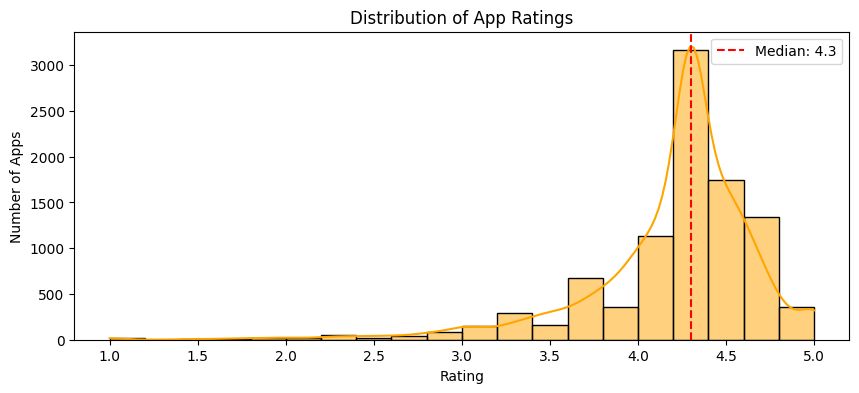

In [41]:
plt.figure(figsize=(10, 4))
sns.histplot(df['Rating'], bins=20, kde=True, color='orange')
plt.axvline(median_rating, color='red', linestyle='--', label=f'Median: {median_rating}')
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')
plt.legend()
plt.show()

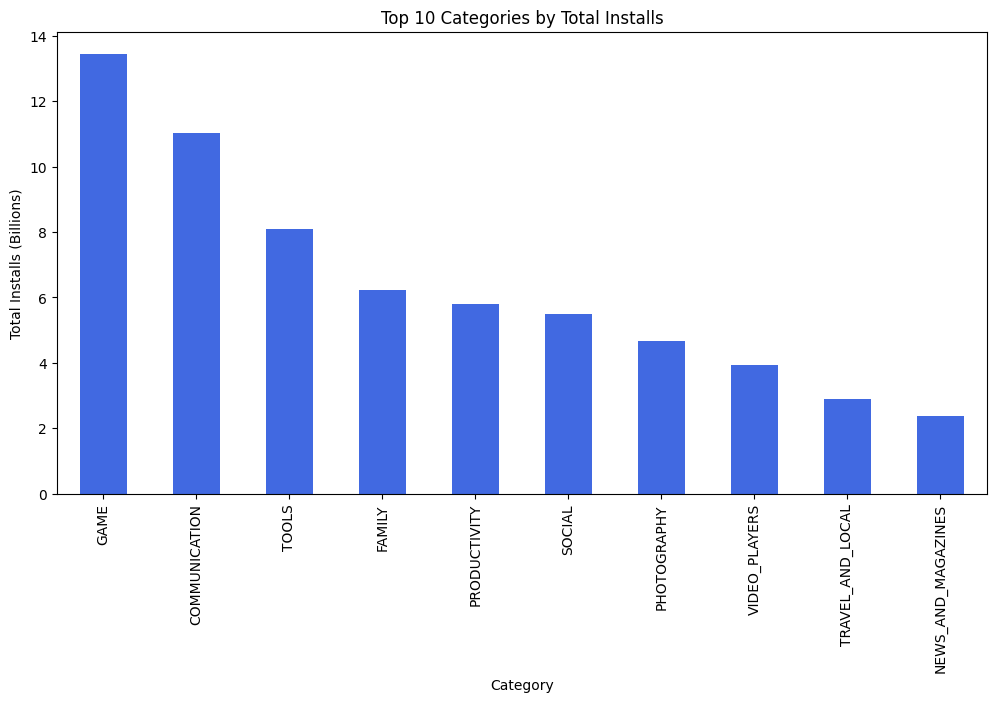

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

installs_per_category = df.groupby('Category')['Installs'].sum().sort_values(ascending=False).head(10) / 1e9

plt.figure(figsize=(12, 6))
installs_per_category.plot(kind='bar', color='royalblue')
plt.title('Top 10 Categories by Total Installs')
plt.ylabel('Total Installs (Billions)')
plt.show()

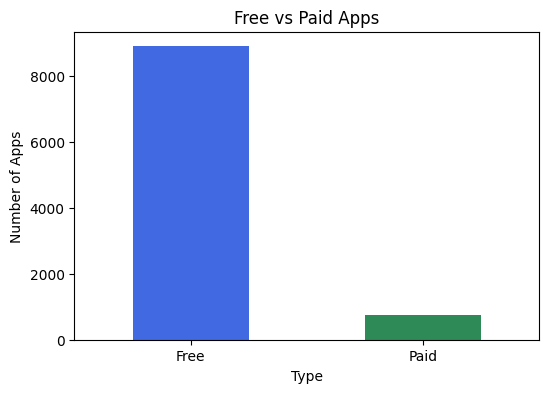

In [43]:
plt.figure(figsize=(6, 4))
df['Type'].value_counts().plot(kind='bar', color=['royalblue', 'seagreen'])
plt.title('Free vs Paid Apps')
plt.ylabel('Number of Apps')
plt.xticks(rotation=0)
plt.show()

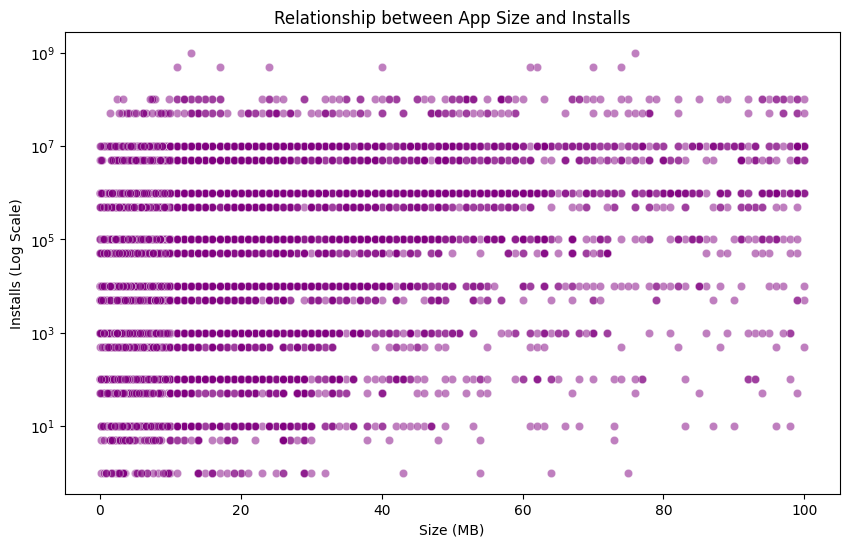

In [44]:
plt.figure(figsize=(10, 6))

sns.scatterplot(x='Size', y='Installs', data=df, alpha=0.5, color='purple')

plt.title('Relationship between App Size and Installs')
plt.xlabel('Size (MB)')
plt.ylabel('Installs (Log Scale)')
plt.yscale('log')
plt.show()

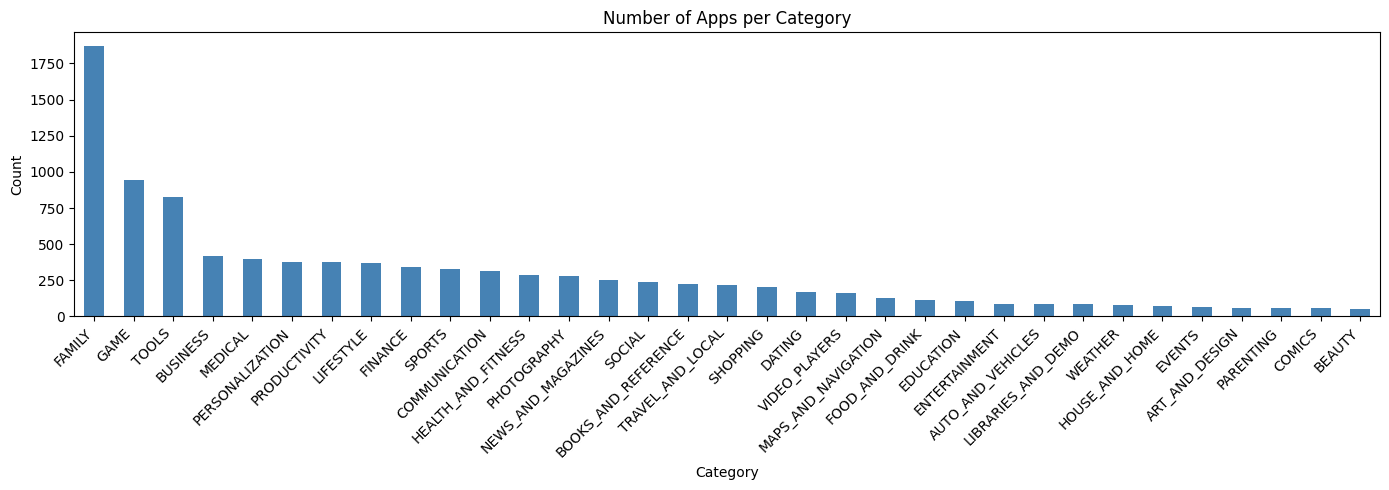

In [45]:
plt.figure(figsize=(14, 5))
df['Category'].value_counts().plot(kind='bar', color='steelblue')
plt.title('Number of Apps per Category')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

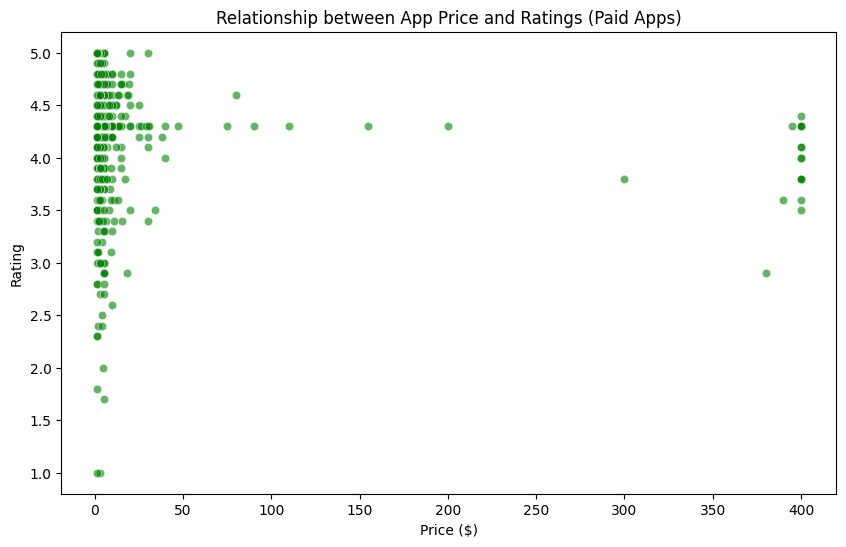

In [46]:
plt.figure(figsize=(10, 6))

paid_apps = df[df['Price'] > 0]
sns.scatterplot(x='Price', y='Rating', data=paid_apps, color='green', alpha=0.6)

plt.title('Relationship between App Price and Ratings (Paid Apps)')
plt.xlabel('Price ($)')
plt.ylabel('Rating')
plt.show()

/tmp/ipykernel_5000/856104402.py:3: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  heatmap_data = df[df['Price'] > 0].pivot_table(index='Category', columns='Price_Range', values='Rating', aggfunc='mean')


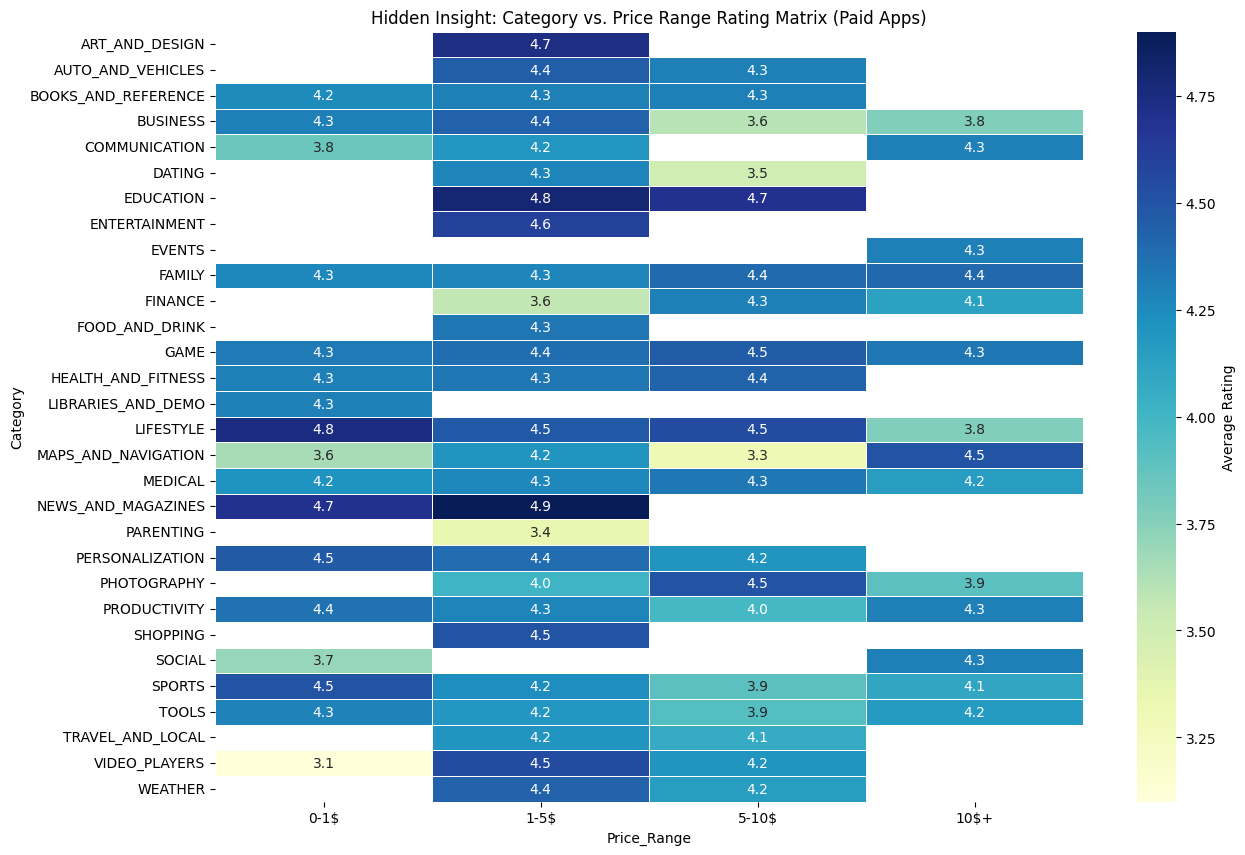

In [47]:
df['Price_Range'] = pd.cut(df['Price'], bins=[-1, 0, 1, 5, 10, float('inf')], labels=['Free', '0-1$', '1-5$', '5-10$', '10$+'])

heatmap_data = df[df['Price'] > 0].pivot_table(index='Category', columns='Price_Range', values='Rating', aggfunc='mean')

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=True, fmt='.1f', linewidths=.5, cbar_kws={'label': 'Average Rating'})
plt.title('Hidden Insight: Category vs. Price Range Rating Matrix (Paid Apps)')
plt.show()

## 8. Before and after
First a table with the main numbers. Then the summary statistics. Before cleaning only `Rating` is a number (Reviews, Size, Installs and Price are text), so only Rating can be described. Look at its max: the broken row made it 19.

In [48]:
before_after = pd.DataFrame({
    'before': [len(df_raw), df_raw.isnull().sum().sum(), df_raw['Rating'].isnull().sum(), df_raw['Size'].isnull().sum(),
               df_raw.duplicated().sum(), df_raw['App'].duplicated().sum(),
               str(df_raw['Installs'].dtype), str(df_raw['Price'].dtype), str(df_raw['Size'].dtype)],
    'after':  [len(df), df.isnull().sum().sum(), df['Rating'].isnull().sum(), df['Size'].isnull().sum(),
               df.duplicated().sum(), df['App'].duplicated().sum(),
               str(df['Installs'].dtype), str(df['Price'].dtype), str(df['Size'].dtype)],
}, index=['rows', 'missing cells (all columns)', 'missing Rating', 'missing Size', 'exact duplicate rows',
          'repeated app names', 'Installs type', 'Price type', 'Size type'])
before_after

,before,after
rows,10841,9656
missing cells (all columns),1487,1237
missing Rating,1474,0
missing Size,0,1227
exact duplicate rows,483,0
repeated app names,1181,0
Installs type,object,int64
Price type,object,float64
Size type,object,float64


In [49]:
print('BEFORE (only Rating is a number)')
print(df_raw['Rating'].describe().round(2))
print()
print('AFTER')
print(df[['Rating', 'Reviews', 'Size', 'Installs', 'Price']].describe().round(2))

BEFORE (only Rating is a number)
count    9367.00
mean        4.19
std         0.54
min         1.00
25%         4.00
50%         4.30
75%         4.50
max        19.00
Name: Rating, dtype: float64

AFTER
        Rating      Reviews     Size      Installs    Price
count  9656.00      9656.00  8429.00  9.656000e+03  9656.00
mean      4.19    216871.35    20.40  7.800588e+06     1.10
std       0.50   1831710.75    21.83  5.377791e+07    16.85
min       1.00         0.00     0.01  0.000000e+00     0.00
25%       4.00        25.00     4.60  1.000000e+03     0.00
50%       4.30       969.50    12.00  1.000000e+05     0.00
75%       4.50     29467.75    28.00  1.000000e+06     0.00
max       5.00  78158306.00   100.00  1.000000e+09   400.00


## 9. Remaining issues (not fixed) and why
- **Filled ratings:** the missing ratings were filled with the median. They are marked in `Rating_was_missing`.
- **Installs are ranges** (like `1,000+`), so the totals are approximate (a lower limit).
- **Size is empty** for the `Varies with device` apps. We do not guess a size.
- **Prices up to 400 dollars:** we looked at them and kept them. They look like real listings (not verified).
- **Repeated apps:** we kept one copy only (the one with the most reviews), so the other copies are gone.
- **Columns not cleaned:** Last Updated, Current Ver and Android Ver are still text. We do not use them here.
- **Content Rating:** the Kaggle page lists different values than the real file. We trust the real file.
- **Old data:** collected in 2018, so the results may not match today.

In [50]:
df.to_csv('/content/drive/MyDrive/googleplaystore_clean.csv', index=False)
print('Saved:', df.shape)

Saved: (9656, 15)
